<a href="https://colab.research.google.com/github/lvi8544851094-eng/aiml-30-days/blob/main/Lab_A_Kaggle_Gradient_Descent_Used_Cars.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab A (Kaggle) · Used Car Prices on GT Road: Dealer's Depreciation Rule vs Gradient Descent from Scratch
**AI/ML Engineer Program · Day 3 (Linear Regression I) · RIMT, Sirhind (B.Tech CSE · 3rd Semester) · 20–25 minutes**

Every used-car dealer at the Ludhiana–Sirhind GT Road car bazaar has a pocket rule for hatchbacks and compact SUVs:
> *"Start at ₹8.5 lakh for a brand-new car, and subtract ₹0.55 lakh for every year on the road."*

That rule **is** a straight line: $\hat{y} = w \cdot x + b$, where $w = -0.55$ (slope) and $b = 8.50$ (intercept).
Today you will:
1. Test your team's hand-picked $(w, b)$ rule on **1,800 used-car listings** (compatible with the Kaggle *Vehicle Dataset from Cardekho* or built automatically below).
2. Write the **Mean Squared Error (MSE) cost function** $J(w, b)$ in 3 lines of NumPy and see the cost bowl.
3. Write **Gradient Descent from scratch** (pure NumPy, zero `scikit-learn` allowed!) so the computer walks down the bowl and finds the best $(w, b)$ itself.
4. Intentionally **break the learning rate $\alpha$** to watch gradient descent crawl or explode to `NaN`, then scale up to all 5 features and match `scikit-learn` to 4 decimal places.

## Step 0 · Load the Kaggle dataset (or build the local copy)
In Kaggle, click **Copy & Edit**. If you attached the *Vehicle Dataset from Cardekho* (`car data.csv`), Step 0 loads it automatically; otherwise it builds a deterministic **1,800-car North India Used Car dataset** (`gt_road_used_cars.csv`, seed `42`) calibrated to 2026 Punjab/NCR resale listings so you never get stuck on Kaggle phone/internet verification.

In [ ]:
# @title ▶ Run me first: Kaggle loader & GT Road Used Car dataset builder
import glob
import numpy as np
import pandas as pd

def build_gt_road_used_cars(n=1800, seed=42):
    rng = np.random.default_rng(seed)
    models = [
        # (model_name, segment, base_new_lakh, annual_drop_lakh, km_drop_per_10k, mileage_kmpl, engine_cc, share)
        ("Maruti Swift VXi",     "Hatchback",   7.8, 0.46, 0.14, 22.3, 1197, 0.20),
        ("Maruti Baleno Delta",  "Hatchback",   8.6, 0.49, 0.15, 22.9, 1197, 0.16),
        ("Hyundai i20 Sportz",   "Hatchback",   9.2, 0.54, 0.16, 20.3, 1197, 0.14),
        ("Tata Nexon XM",        "Compact SUV", 10.8, 0.58, 0.17, 17.4, 1199, 0.15),
        ("Maruti Brezza VXi",    "Compact SUV", 11.2, 0.56, 0.15, 19.8, 1462, 0.13),
        ("Hyundai Creta EX",     "Mid SUV",     13.5, 0.65, 0.18, 17.0, 1497, 0.12),
        ("Honda City V",         "Sedan",       13.0, 0.68, 0.19, 18.4, 1498, 0.10),
    ]
    probs = [m[7] for m in models]
    idx = rng.choice(len(models), size=n, p=probs)
    cities = rng.choice(["Ludhiana", "Chandigarh", "Mohali", "Patiala", "Jalandhar", "Ambala"],
                        size=n, p=[0.26, 0.24, 0.18, 0.12, 0.12, 0.08])

    rows = []
    for i, m_i in enumerate(idx):
        name, seg, base_new, drop_yr, drop_10k, mpl, cc, _ = models[m_i]
        age = np.round(rng.uniform(0.5, 11.5), 1)
        km = int(np.clip(age * rng.normal(10500, 2600) + rng.normal(2000, 3000), 1500, 165000))
        owners = int(rng.choice([1, 2, 3], p=[0.74, 0.21, 0.05]))
        onroad_lakh = round(base_new * rng.uniform(0.95, 1.08), 2)

        # True underlying linear + mild noise relationship
        true_price = (
            0.78 * onroad_lakh
            - 0.42 * age
            - 0.15 * (km / 10000.0)
            - 0.28 * (owners - 1)
            + 0.03 * (mpl - 20.0)
            + rng.normal(0.0, 0.48)
        )
        resale_lakh = round(max(1.15, true_price), 2)
        rows.append({
            "car_id": f"PB-{1000 + i}",
            "city": cities[i],
            "model": name,
            "segment": seg,
            "age_years": age,
            "km_driven": km,
            "owners": owners,
            "mileage_kmpl": round(mpl + rng.normal(0, 0.7), 1),
            "engine_cc": cc,
            "onroad_new_lakh": onroad_lakh,
            "resale_price_lakh": resale_lakh,
        })

    df = pd.DataFrame(rows)

    # Inject realistic portal mess (just like real Cardekho/OLX scrapes):
    # 1) 14 duplicate broker reposts
    dupes = df.sample(14, random_state=seed).copy()
    dupes["car_id"] = [f"PB-DUP-{k}" for k in range(len(dupes))]
    df = pd.concat([df, dupes], ignore_index=True)

    # 2) 3 prices typed in raw rupees instead of lakh (e.g., 540000 instead of 5.4)
    bad_idx = [15, 240, 890]
    df.loc[bad_idx, "resale_price_lakh"] = df.loc[bad_idx, "resale_price_lakh"] * 100000

    # 3) 4 cars with odometer typed as 0 km on a 6+ year old car
    df.loc[[42, 310, 715, 1205], "km_driven"] = 0

    return df

kaggle_files = glob.glob("/kaggle/input/**/gt_road_used_cars.csv", recursive=True) + glob.glob("gt_road_used_cars.csv")
if kaggle_files:
    raw_df = pd.read_csv(kaggle_files[0])
    print("Loaded from file:", kaggle_files[0])
else:
    raw_df = build_gt_road_used_cars(n=1800, seed=42)
    raw_df.to_csv("gt_road_used_cars.csv", index=False)
    print("Built dataset and saved gt_road_used_cars.csv")

print(f"Total rows loaded: {len(raw_df):,}")
print("READY - raise your hand if you can see this line.")

Built dataset and saved gt_road_used_cars.csv
Total rows loaded: 1,814
READY - raise your hand if you can see this line.


## Step 1 · Inspect the data and spot the portal mess
Before writing any math, look at the first 5 rows and check for broken broker entries (reposts, `0 km` odometers on old cars, or prices typed in rupees instead of lakh).

In [ ]:
df = raw_df.copy()
display(df.head(5))

dupes = df.duplicated(subset=df.columns.drop("car_id"))
print("Duplicate broker reposts     :", dupes.sum())
print("Odometer typed as 0 km       :", (df["km_driven"] == 0).sum())
print("Price > ₹100 lakh (rupee bug):", (df["resale_price_lakh"] > 100).sum(),
      f"(max seen: {df['resale_price_lakh'].max():,.0f} lakh)")

# Clean the portal errors
df = df[~dupes].copy()
df = df[(df["km_driven"] > 0) & (df["resale_price_lakh"] <= 100)].reset_index(drop=True)
print(f"Clean listings ready for modelling: {len(df):,}")

Duplicate broker reposts     : 14
Odometer typed as 0 km       : 4
Price > ₹100 lakh (rupee bug): 3 (max seen: 825,000 lakh)
Clean listings ready for modelling: 1,793


,car_id,city,model,segment,age_years,km_driven,owners,mileage_kmpl,engine_cc,onroad_new_lakh,resale_price_lakh
0,PB-1000,Mohali,Maruti Brezza VXi,Compact SUV,3.7,40309,1,19.6,1462,12.00,7.21
1,PB-1001,Mohali,Hyundai i20 Sportz,Hatchback,3.2,32646,1,20.2,1197,9.13,4.56
2,PB-1002,Ludhiana,Hyundai Creta EX,Mid SUV,7.1,77023,1,17.7,1497,13.39,5.58
3,PB-1003,Patiala,Maruti Brezza VXi,Compact SUV,3.6,45436,1,20.1,1462,11.46,6.67
4,PB-1004,Mohali,Maruti Swift VXi,Hatchback,7.6,73791,3,21.8,1197,8.02,1.74


**Why did we drop those 3 rupee-bug rows right away?**
Because Linear Regression minimizes **Mean Squared Error** $(\hat{y} - y)^2$. A single listing typed as `5,40,000` lakh instead of `5.4` lakh has a squared error of $\approx 2.9 \times 10^{11}$ — enough to yank the entire regression line vertically and ruin predictions for all 1,793 normal cars!

## Step 2 · Single-feature problem: predict `resale_price_lakh` from `age_years`
To see the line and the cost bowl clearly in 2D, let's first use a single feature $x = \text{age\_years}$ to predict $y = \text{resale\_price\_lakh}$ on an 80/20 train-test split.

In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.20, random_state=42)

x_train = train_df["age_years"].to_numpy()
y_train = train_df["resale_price_lakh"].to_numpy()
x_test  = test_df["age_years"].to_numpy()
y_test  = test_df["resale_price_lakh"].to_numpy()

def report_score(name, y_true, y_pred):
    mae = np.mean(np.abs(y_pred - y_true))
    mse = np.mean((y_pred - y_true) ** 2)
    pct_within_15 = np.mean(np.abs(y_pred - y_true) / y_true <= 0.15) * 100
    print(f"{name:<34} | MAE: ₹{mae:4.2f}L | MSE: {mse:5.2f} | Within ±15%: {pct_within_15:5.1f}%")

# Baseline: always guess the median training price
baseline_pred = np.full_like(y_test, np.median(y_train))
print(f"Training cars: {len(x_train)} | Test cars: {len(x_test)} | Median train price: ₹{np.median(y_train):.2f}L\n")
report_score("0. Always guess the median", y_test, baseline_pred)

Training cars: 1434 | Test cars: 359 | Median train price: ₹4.60L

0. Always guess the median         | MAE: ₹1.96L | MSE:  5.58 | Within ±15%:  21.7%


## Step 3 · Your team's hypothesis line: $\hat{y} = w \cdot x + b$
In class your team picked a starting price $b$ (when `age_years = 0`) and a yearly depreciation slope $w$ (how many lakh the car loses per year).
Edit `YOUR_SLOPE_W` and `YOUR_INTERCEPT_B` below and run the cell to test your line on the 359 test cars!

In [ ]:
# <--- EDIT THESE TWO NUMBERS WITH YOUR TEAM'S GUESS --->
YOUR_SLOPE_W     = -0.55   # ₹ lakh lost per year of age (negative because older cars cost less)
YOUR_INTERCEPT_B =  8.50   # ₹ lakh starting price at age = 0 years

def predict_line(x, w, b):
    return w * x + b

rule_test_pred = predict_line(x_test, YOUR_SLOPE_W, YOUR_INTERCEPT_B)
report_score("0. Always guess the median", y_test, baseline_pred)
report_score(f"1. Team rule (w={YOUR_SLOPE_W}, b={YOUR_INTERCEPT_B})", y_test, rule_test_pred)

0. Always guess the median         | MAE: ₹1.96L | MSE:  5.58 | Within ±15%:  21.7%
1. Team rule (w=-0.55, b=8.5)      | MAE: ₹1.55L | MSE:  3.10 | Within ±15%:  20.1%


## Step 4 · The Cost Function $J(w, b)$: measuring the bowl
How does the machine know whether $(w=-0.55, b=8.50)$ is the best possible line?
It computes the **Mean Squared Error (MSE) cost function** over all $m$ training examples:
$$J(w, b) = \frac{1}{2m} \sum_{i=1}^{m} \left(\hat{y}^{(i)} - y^{(i)}\right)^2 = \frac{1}{2m} \sum_{i=1}^{m} \left(w x^{(i)} + b - y^{(i)}\right)^2$$
Why divide by $2m$ instead of $m$? Because when we take the derivative of $(\dots)^2$, the $2$ comes down to the front and cancels out cleanly!

In [ ]:
def compute_cost(x, y, w, b):
    m = len(y)
    y_hat = w * x + b
    return np.sum((y_hat - y) ** 2) / (2 * m)

team_cost = compute_cost(x_train, y_train, YOUR_SLOPE_W, YOUR_INTERCEPT_B)
print(f"Cost J(w, b) for your team's line ({YOUR_SLOPE_W}, {YOUR_INTERCEPT_B}): {team_cost:.4f}")

# Let's test a few neighbouring (w, b) pairs to feel the shape of the bowl:
for w_try, b_try in [(-0.80, 9.50), (-0.55, 8.50), (-0.49, 7.75), (-0.20, 6.00)]:
    print(f"  w = {w_try:5.2f}, b = {b_try:5.2f}  -->  J(w, b) = {compute_cost(x_train, y_train, w_try, b_try):6.4f}")

Cost J(w, b) for your team's line (-0.55, 8.5): 1.4430
  w = -0.80, b =  9.50  -->  J(w, b) = 1.5825
  w = -0.55, b =  8.50  -->  J(w, b) = 1.4430
  w = -0.49, b =  7.75  -->  J(w, b) = 1.3048
  w = -0.20, b =  6.00  -->  J(w, b) = 1.8839


## Step 5 · Gradient Descent from Scratch (NumPy only!)
Instead of guessing $(w, b)$ by hand, we let **Gradient Descent** walk downhill on the cost bowl $J(w, b)$.
At each step, we compute the partial derivatives (the slope of the bowl in the $w$ and $b$ directions):
$$\frac{\partial J}{\partial w} = \frac{1}{m} \sum_{i=1}^{m} \left(\hat{y}^{(i)} - y^{(i)}\right) x^{(i)}, \qquad \frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} \left(\hat{y}^{(i)} - y^{(i)}\right)$$
Then we update **both** parameters simultaneously using learning rate $\alpha$:
$$w \leftarrow w - \alpha \frac{\partial J}{\partial w}, \qquad b \leftarrow b - \alpha \frac{\partial J}{\partial b}$$

> **Engineering habit:** We standardize $x$ first ($x_{\text{scaled}} = \frac{x - \mu}{\sigma}$) so the cost bowl is round rather than a narrow canyon, then convert $(w, b)$ back to original units (`₹ lakh per year`) at the end.

In [ ]:
# Standardize x_train using ONLY training mean and std (never leak test statistics!)
x_mean = np.mean(x_train)
x_std  = np.std(x_train)
x_train_sc = (x_train - x_mean) / x_std

def gradient_descent_1d(x_sc, y, lr=0.10, epochs=120):
    m = len(y)
    w_sc, b_sc = 0.0, 0.0
    history = []

    for epoch in range(epochs):
        y_hat = w_sc * x_sc + b_sc
        err   = y_hat - y
        dj_dw = np.dot(err, x_sc) / m
        dj_db = np.mean(err)

        w_sc = w_sc - lr * dj_dw
        b_sc = b_sc - lr * dj_db
        history.append(compute_cost(x_sc, y, w_sc, b_sc))

    return w_sc, b_sc, np.array(history)

w_sc, b_sc, cost_history = gradient_descent_1d(x_train_sc, y_train, lr=0.10, epochs=120)

# Convert scaled parameters back to raw units: y_hat = w_sc * ((x - x_mean)/x_std) + b_sc
w_gd = w_sc / x_std
b_gd = b_sc - (w_sc * x_mean / x_std)

print(f"Learned by Gradient Descent -> slope w = {w_gd:.4f} ₹L/yr | intercept b = {b_gd:.4f} ₹L")
print(f"Starting Cost J(0, 0): {cost_history[0]:.4f}  -->  Final Cost J(w*, b*): {cost_history[-1]:.4f}\n")

gd_1d_pred = predict_line(x_test, w_gd, b_gd)
report_score("0. Always guess the median", y_test, baseline_pred)
report_score(f"1. Team rule (w={YOUR_SLOPE_W}, b={YOUR_INTERCEPT_B})", y_test, rule_test_pred)
report_score(f"2. NumPy Gradient Descent (1 feature)", y_test, gd_1d_pred)

Learned by Gradient Descent -> slope w = -0.5498 ₹L/yr | intercept b = 7.9071 ₹L
Starting Cost J(0, 0): 11.2504  -->  Final Cost J(w*, b*): 1.2678

0. Always guess the median         | MAE: ₹1.96L | MSE:  5.58 | Within ±15%:  21.7%
1. Team rule (w=-0.55, b=8.5)      | MAE: ₹1.55L | MSE:  3.10 | Within ±15%:  20.1%
2. NumPy Gradient Descent (1 feature) | MAE: ₹1.42L | MSE:  2.73 | Within ±15%:  22.8%


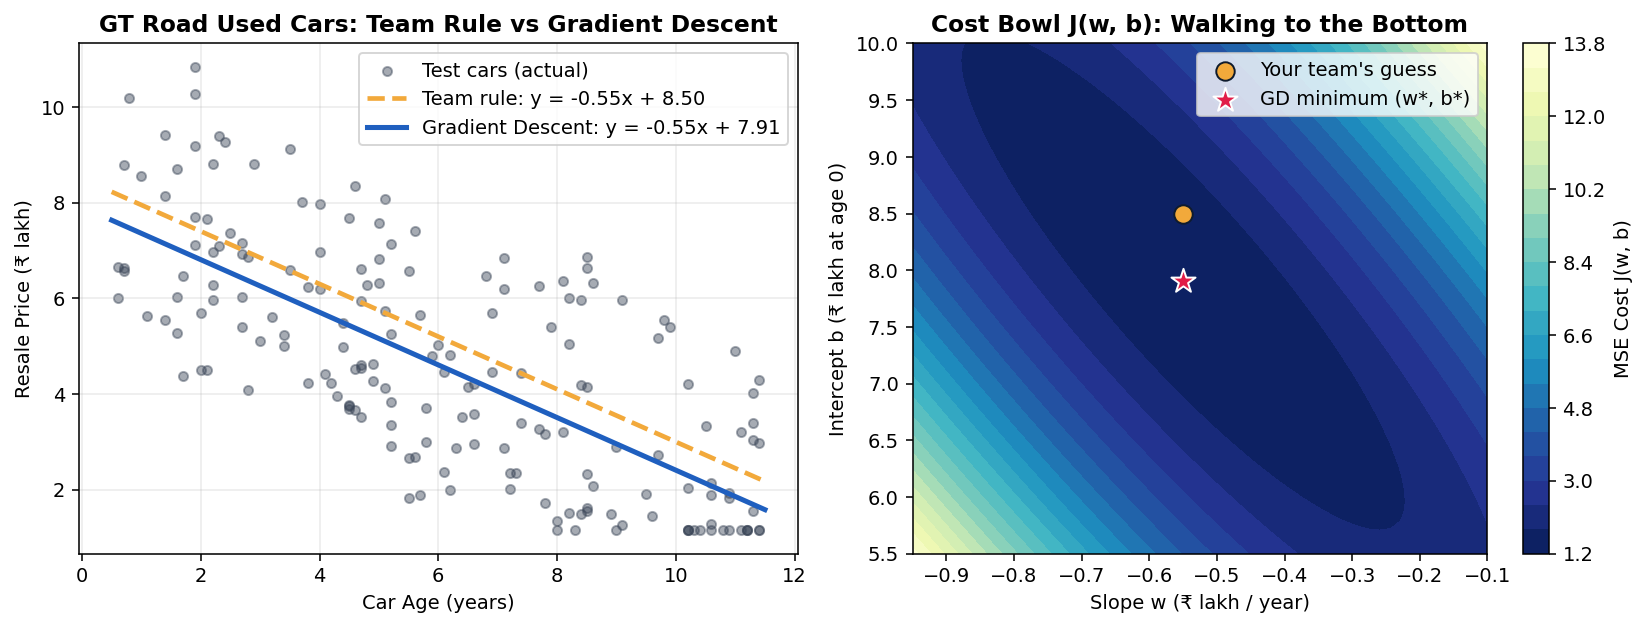

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

# Left plot: Data + Team Rule vs Learned GD Line
ax1.scatter(x_test[:180], y_test[:180], alpha=0.45, s=22, color="#3B4658", label="Test cars (actual)")
x_line = np.linspace(0.5, 11.5, 100)
ax1.plot(x_line, predict_line(x_line, YOUR_SLOPE_W, YOUR_INTERCEPT_B), "--", color="#F2A93B", linewidth=2.4,
         label=f"Team rule: y = {YOUR_SLOPE_W:.2f}x + {YOUR_INTERCEPT_B:.2f}")
ax1.plot(x_line, predict_line(x_line, w_gd, b_gd), "-", color="#1F5FBF", linewidth=2.6,
         label=f"Gradient Descent: y = {w_gd:.2f}x + {b_gd:.2f}")
ax1.set_title("GT Road Used Cars: Team Rule vs Gradient Descent", fontsize=12, fontweight="bold")
ax1.set_xlabel("Car Age (years)")
ax1.set_ylabel("Resale Price (₹ lakh)")
ax1.legend(frameon=True)
ax1.grid(alpha=0.25)

# Right plot: Cost J(w, b) Bowl Contour + GD Path
W_grid = np.linspace(-0.95, -0.10, 60)
B_grid = np.linspace(5.50, 10.00, 60)
J_grid = np.zeros((len(B_grid), len(W_grid)))
for i_b, b_val in enumerate(B_grid):
    for j_w, w_val in enumerate(W_grid):
        J_grid[i_b, j_w] = compute_cost(x_train, y_train, w_val, b_val)

cs = ax2.contourf(W_grid, B_grid, J_grid, levels=20, cmap="YlGnBu_r")
plt.colorbar(cs, ax=ax2, label="MSE Cost J(w, b)")
ax2.scatter([YOUR_SLOPE_W], [YOUR_INTERCEPT_B], color="#F2A93B", s=90, edgecolor="#0F1B2D", zorder=5, label="Your team's guess")
ax2.scatter([w_gd], [b_gd], color="#E11D48", marker="*", s=170, edgecolor="white", zorder=6, label="GD minimum (w*, b*)")
ax2.set_title("Cost Bowl J(w, b): Walking to the Bottom", fontsize=12, fontweight="bold")
ax2.set_xlabel("Slope w (₹ lakh / year)")
ax2.set_ylabel("Intercept b (₹ lakh at age 0)")
ax2.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()

## Step 6 · Break the Learning Rate $\alpha$ (Live Experiment)
What happens if an engineer picks the wrong learning rate $\alpha$?
Let's run our exact same `gradient_descent_1d` function for 40 epochs with three different values of $\alpha$:
- **Too small (`lr = 0.005`)**: Tiny baby steps — barely moves in 40 epochs.
- **Just right (`lr = 0.15`)**: Smooth, fast drop straight to the bottom of the bowl.
- **Too large (`lr = 2.12`)**: Overshoots the opposite wall of the bowl on every step — cost **increases** and explodes!

lr = 0.005 (too small) -> Epoch 0: 13.47 | Epoch 39: 9.52 (still far from minimum!)
lr = 0.150 (just right)-> Epoch 0: 10.17 | Epoch 39: 1.27 (converged!)
lr = 2.120 (too large) -> Epoch 0: 16.73 | Epoch 14: 370.50 (EXPLODING uphill!)


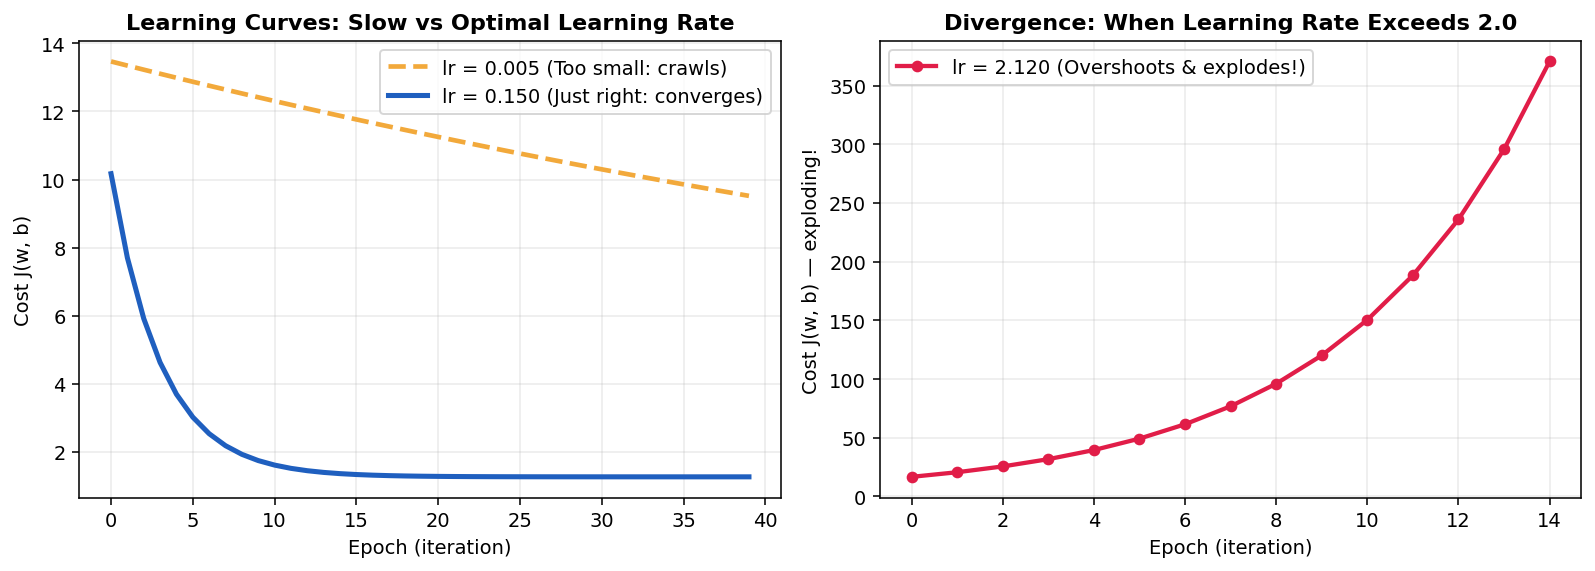

In [ ]:
_, _, hist_slow = gradient_descent_1d(x_train_sc, y_train, lr=0.005, epochs=40)
_, _, hist_good = gradient_descent_1d(x_train_sc, y_train, lr=0.150, epochs=40)
_, _, hist_boom = gradient_descent_1d(x_train_sc, y_train, lr=2.120, epochs=15)

print(f"lr = 0.005 (too small) -> Epoch 0: {hist_slow[0]:.2f} | Epoch 39: {hist_slow[-1]:.2f} (still far from minimum!)")
print(f"lr = 0.150 (just right)-> Epoch 0: {hist_good[0]:.2f} | Epoch 39: {hist_good[-1]:.2f} (converged!)")
print(f"lr = 2.120 (too large) -> Epoch 0: {hist_boom[0]:.2f} | Epoch 14: {hist_boom[-1]:,.2f} (EXPLODING uphill!)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax1.plot(hist_slow, "--", color="#F2A93B", linewidth=2.4, label="lr = 0.005 (Too small: crawls)")
ax1.plot(hist_good, "-",  color="#1F5FBF", linewidth=2.6, label="lr = 0.150 (Just right: converges)")
ax1.set_title("Learning Curves: Slow vs Optimal Learning Rate", fontsize=11.5, fontweight="bold")
ax1.set_xlabel("Epoch (iteration)")
ax1.set_ylabel("Cost J(w, b)")
ax1.legend()
ax1.grid(alpha=0.25)

ax2.plot(hist_boom, "-o", color="#E11D48", linewidth=2.2, markersize=5, label="lr = 2.120 (Overshoots & explodes!)")
ax2.set_title("Divergence: When Learning Rate Exceeds 2.0", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Epoch (iteration)")
ax2.set_ylabel("Cost J(w, b) — exploding!")
ax2.legend()
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Step 7 · Multi-Feature Gradient Descent vs `scikit-learn`
A real car dealer doesn't just look at `age_years`. They also check **`onroad_new_lakh`** (what the car cost new), **`km_driven`**, **`owners`**, and **`mileage_kmpl`**.
Let's run multi-feature Gradient Descent in pure NumPy on all 5 numeric clues:
$$\hat{\mathbf{y}} = X \mathbf{w} + b$$
and compare our learned weights and test-set MAE against `sklearn.linear_model.LinearRegression`!

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

features = ["onroad_new_lakh", "age_years", "km_driven", "owners", "mileage_kmpl"]
X_tr_raw = train_df[features].to_numpy(dtype=float)
X_te_raw = test_df[features].to_numpy(dtype=float)

# Standardize all 5 features using training mean and std
mu = X_tr_raw.mean(axis=0)
sigma = X_tr_raw.std(axis=0)
X_tr = (X_tr_raw - mu) / sigma
X_te = (X_te_raw - mu) / sigma

def gradient_descent_multi(X, y, lr=0.15, epochs=400):
    m, d = X.shape
    w = np.zeros(d)
    b = 0.0
    for _ in range(epochs):
        err = (X @ w + b) - y
        w -= lr * (X.T @ err) / m
        b -= lr * np.mean(err)
    return w, b

w_multi_sc, b_multi_sc = gradient_descent_multi(X_tr, y_train, lr=0.15, epochs=400)
gd_5f_pred = X_te @ w_multi_sc + b_multi_sc

# Compare against scikit-learn LinearRegression
sk_model = LinearRegression()
sk_model.fit(X_tr, y_train)
sk_pred = sk_model.predict(X_te)

print("=== FINAL SCOREBOARD ON 359 TEST CARS ===")
report_score("0. Always guess the median", y_test, baseline_pred)
report_score(f"1. Team rule (age only)", y_test, rule_test_pred)
report_score("2. NumPy GD (1 feature: age)", y_test, gd_1d_pred)
report_score("3. Pure NumPy GD (all 5 features)", y_test, gd_5f_pred)
report_score("4. scikit-learn LinearRegression", y_test, sk_pred)

print(f"\nR² Score (5-feature NumPy GD) : {r2_score(y_test, gd_5f_pred):.4f}")
print(f"Max weight difference vs sklearn: {np.max(np.abs(w_multi_sc - sk_model.coef_)):.2e}")

coef_table = pd.DataFrame({
    "Feature": features,
    "NumPy_GD_Scaled_Weight": np.round(w_multi_sc, 4),
    "Sklearn_Scaled_Weight":  np.round(sk_model.coef_, 4),
})
display(coef_table)

=== FINAL SCOREBOARD ON 359 TEST CARS ===
0. Always guess the median         | MAE: ₹1.96L | MSE:  5.58 | Within ±15%:  21.7%
1. Team rule (age only)            | MAE: ₹1.55L | MSE:  3.10 | Within ±15%:  20.1%
2. NumPy GD (1 feature: age)       | MAE: ₹1.42L | MSE:  2.73 | Within ±15%:  22.8%
3. Pure NumPy GD (all 5 features)  | MAE: ₹0.40L | MSE:  0.27 | Within ±15%:  74.1%
4. scikit-learn LinearRegression   | MAE: ₹0.40L | MSE:  0.27 | Within ±15%:  74.1%

R² Score (5-feature NumPy GD) : 0.9524
Max weight difference vs sklearn: 3.02e-04


,Feature,NumPy_GD_Scaled_Weight,Sklearn_Scaled_Weight
0,onroad_new_lakh,1.5545,1.5545
1,age_years,-1.3448,-1.3451
2,km_driven,-0.4140,-0.4137
3,owners,-0.1335,-0.1335
4,mileage_kmpl,0.0825,0.0825
